# Notebook 11: Estructura cuántica por caso de uso (mismos indicadores, mismo protocolo)

## Reencuadre
Hasta el notebook 09 se miraba la *ventaja* (accuracy, $R^2$, AUC, coste) caso por caso y
con métricas distintas. Aquí cambia la pregunta:

> **¿Tiene cada problema estructura que un kernel cuántico (ZZFeatureMap) represente de forma
> distinta a un kernel clásico RBF?**

- $Q(D)$ se trata como un **vector de indicadores de estructura**, no como un escalar de decisión.
- Se miden **los mismos cinco indicadores** en **los mismos protocolos** para cuatro casos de uso:
  clasificación, regresión, detección de anomalías y optimización.
- **No** aparece accuracy, $R^2$, AUC ni coste de solución. Nada de lo que se grafica sale de una ventaja supervisada.
- Se incluye un **control nulo** (etiquetas permutadas) para saber qué es ruido.
- Se dejan explícitas las **limitaciones**; si un resultado es un artefacto, se dice.

## Indicadores (los de la diapositiva "Indicadores implementados")
| Indicador | Definición | Referencia |
|---|---|---|
| Kernel Alignment $\Delta A$ | $A(K_Q,yy^\top)-A(K_{\rm RBF},yy^\top)$ (alineación centrada) | Cortes et al. 2012; Huang et al. 2021 |
| Entropía espectral $\Delta H$ | $H(K_Q)-H(K_{\rm RBF})$ | Thanasilp et al. 2022 |
| Distancia Frobenius $d_F$ | $\lVert K_Q-K_{\rm RBF}\rVert_F/n$ (kernels normalizados) | Liu et al. 2021 |
| Diferencia geométrica $g$ | $\sqrt{\lVert K_Q^{1/2}K_{\rm RBF}^{-1}K_Q^{1/2}\rVert_F}$ | Huang et al. 2021 |
| Compuesto $\mathcal Q$ | $0.4\,\Delta A+0.3\,\hat d_F+0.3\,\Delta H$, con $\hat d_F=d_F/\max d_F$ | Este TFM (solo informativo) |

**Detalle clave:** solo $\Delta A$ usa $y$. $\Delta H$, $d_F$ y $g$ dependen únicamente de $X$ (y del protocolo de
codificación). Lo que dicen es *cómo se ve el conjunto de puntos a través del kernel*, no si la tarea tiene estructura cuántica.

## §1 — Imports y configuración

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

POCS = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "qml_v2").exists())
sys.path.insert(0, str(POCS))
sys.path.insert(0, str(POCS / "scripts"))

from qml_v2 import estructura_casos as ec

FIGURES = POCS / "data" / "output" / "figures"
METRICS = POCS / "data" / "output" / "metrics"
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUES = ["#0D47A1", "#1976D2", "#90CAF9"]
print("Protocolo:", ec.CFG)

Protocolo: QuantumnessConfig(n_qubits=2, zz_reps=2, entanglement='full', n_sample=60, test_size=0.3, random_state=42, n_repeats=3, lambda_geom=0.35, gate_kappa=20.0, d_f_ref=1.0, svm_C=1.0, w_delta_a=0.4, w_d_f=0.3, w_delta_h=0.3, ci_low=0.1, ci_high=0.9, alpha_grid=(0.0, 0.25, 0.5, 0.75, 1.0), alpha_n=80)


## §2 — Protocolo único
- `ZZFeatureMap`, 2 qubits, `reps=2`, entrelazamiento `full`; kernel de fidelidad exacto (statevector).
- Codificación: `StandardScaler → PCA(2) → MinMax[−π, π]`. Los datasets *nativos* ya viven en el espacio ZZ y no se transforman.
- Submuestra de 60 puntos, 3 repeticiones (semillas $42+17r$).
- Baseline clásico: RBF con $\sigma$ elegido por **cercanía de Frobenius a $K_Q$** (no mira las etiquetas).
- Control nulo: la misma $X$ con $y$ permutada; ΔA nulo = ruido de la métrica.

## §3 — Qué es "un caso de uso" en optimización
Un problema de optimización **no es** un par $(X,y)$. Para poder pasar por el *mismo* pipeline se usa el **paisaje del QUBO**:

- $X$ = **todos** los bitstrings del espacio de búsqueda (512 para asignación $n{=}3$ y TSP $n{=}4$; 1024 para MaxCut $n{=}10$).
- $y$ = energía del QUBO tras la conversión `QuadraticProgramToQubo` (con penalización de restricciones, exactamente lo que ve QAOA).

Es un **test de estructura del paisaje**, no una medida de rendimiento de QAOA y no es comparable con la ventaja de coste de los notebooks 02/05.
Los roles de la defensa se conservan solo como posición de barra (Nativo = asignación, SKG-like = MaxCut, Referencia = TSP).
El módulo `qml_v2.maxcutm_optimization` implementa **MaxCut**; la diapositiva lo llama "MDS (cobertura)" y aquí se mide lo que realmente existe en el código: MaxCut.

### 3.1 Los paisajes que ve el kernel

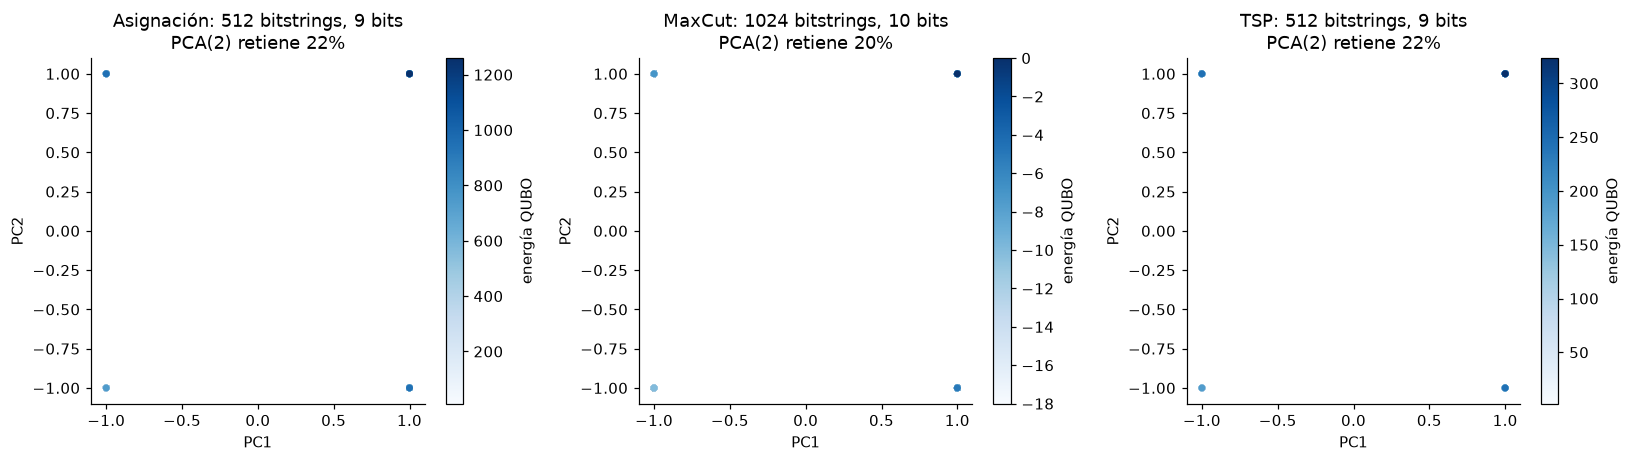

,problema,instancias,bits,estados,energía min,energía max,frac. en el mínimo
0,Asignación,5,9,512,11.515,1259.991,0.002
1,MaxCut,5,10,1024,-18.000,0.000,0.006
2,TSP,3,9,512,2.273,323.514,0.004


In [2]:
opt_jobs = ec.optimization_jobs()
rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, job in zip(axes, opt_jobs):
    X, y = job.instances[0]
    Z = PCA(2, random_state=0).fit(StandardScaler().fit_transform(X))
    P = Z.transform(StandardScaler().fit_transform(X))
    sc = ax.scatter(P[:, 0], P[:, 1], c=y, cmap="Blues", s=12)
    ax.set_title(f"{job.name}: {len(X)} bitstrings, {X.shape[1]} bits\nPCA(2) retiene {Z.explained_variance_ratio_.sum():.0%}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    plt.colorbar(sc, ax=ax, label="energía QUBO")
    rows.append({"problema": job.name, "instancias": len(job.instances), "bits": X.shape[1],
                 "estados": len(X), "energía min": y.min(), "energía max": y.max(),
                 "frac. en el mínimo": float(np.mean(np.isclose(y, y.min())))})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

**Debilidad que hay que decir en voz alta:** PCA(2) retiene solo ~⅓ de la varianza de los bitstrings. El kernel cuántico de 2 qubits ve una
proyección muy pobre del paisaje; un resultado "plano" aquí es en parte consecuencia de ese cuello de botella (2 qubits ≪ 9–10 variables),
no solo una propiedad del problema.

## §4 — Medición (los 12 casos, mismo protocolo)

In [3]:
RECOMPUTE = True   # ~5-6 min; con False se reutiliza el CSV existente
csv = METRICS / "estructura_por_caso_uso.csv"
if RECOMPUTE or not csv.exists():
    df = ec.measure_all(include_optimization=True, verbose=True)
    df.to_csv(csv, index=False)
else:
    df = pd.read_csv(csv)
print("\nGuardado:", csv)

  [clasificacion] Nativo       ΔA=+0.1970 (nulo +0.0339±0.0223)  ΔH=1.980  d_F=0.0102  g=3204  pcaVar=1.00  (14.0s)


  [clasificacion] SKG          ΔA=-0.0099 (nulo -0.0056±0.0242)  ΔH=1.673  d_F=0.0105  g=2758  pcaVar=0.59  (13.8s)


  [clasificacion] Telco        ΔA=-0.0945 (nulo +0.0334±0.0297)  ΔH=1.951  d_F=0.0104  g=3189  pcaVar=0.38  (13.8s)


  [regresion    ] Nativo       ΔA=+0.2796 (nulo +0.0507±0.0247)  ΔH=2.056  d_F=0.0104  g=3290  pcaVar=1.00  (13.6s)


  [regresion    ] Friedman     ΔA=-0.3233 (nulo +0.0218±0.0235)  ΔH=2.001  d_F=0.0110  g=3191  pcaVar=0.53  (13.7s)


...

  [anomalias    ] SKG          ΔA=-0.2530 (nulo +0.0370±0.0219)  ΔH=0.440  d_F=0.0092  g=1060  pcaVar=0.63  (14.0s)


  [anomalias    ] moons        ΔA=-0.0082 (nulo +0.0412±0.0105)  ΔH=1.864  d_F=0.0103  g=3200  pcaVar=1.00  (13.8s)


  [optimizacion ] Asignación   ΔA=-0.0797 (nulo +0.0313±0.0278)  ΔH=2.000  d_F=0.0108  g=3274  pcaVar=0.33  (68.7s)


  [optimizacion ] MaxCut       ΔA=+0.0373 (nulo +0.0409±0.0242)  ΔH=2.022  d_F=0.0107  g=3253  pcaVar=0.31  (68.6s)


  [optimizacion ] TSP          ΔA=-0.0665 (nulo +0.0376±0.0326)  ΔH=2.022  d_F=0.0108  g=3314  pcaVar=0.32  (41.4s)

Guardado: /workspace/POCs/data/output/metrics/estructura_por_caso_uso.csv


In [4]:
df["z_vs_nulo"] = (df["delta_A"] - df["delta_A_null"]) / df["delta_A_null_std"].replace(0, np.nan)
cols = ["family", "dataset", "delta_A", "delta_A_null", "z_vs_nulo", "delta_H", "d_F", "g", "pca_var"]
df[cols].round(4)

,family,dataset,delta_A,delta_A_null,z_vs_nulo,delta_H,d_F,g,pca_var
0,clasificacion,Nativo,0.1970,0.0339,7.3127,1.9800,0.0102,3203.8634,1.0000
1,clasificacion,SKG,-0.0099,-0.0056,-0.1770,1.6732,0.0105,2757.7307,0.5950
2,clasificacion,Telco,-0.0945,0.0334,-4.3039,1.9508,0.0104,3189.4129,0.3776
3,regresion,Nativo,0.2796,0.0507,9.2695,2.0564,0.0104,3289.7402,1.0000
4,regresion,Friedman,-0.3233,0.0218,-14.7127,2.0013,0.0110,3191.4812,0.5339
5,regresion,SKG,-0.0448,0.0410,-6.2609,1.9331,0.0108,3066.5384,0.7570
6,anomalias,zz_phase,0.0914,-0.0276,2.8885,1.9816,0.0097,3265.3442,1.0000
7,anomalias,SKG,-0.2530,0.0370,-13.2689,0.4404,0.0092,1060.0426,0.6277
8,anomalias,moons,-0.0082,0.0412,-4.6809,1.8639,0.0103,3200.3932,1.0000
9,optimizacion,Asignación,-0.0797,0.0313,-3.9908,2.0001,0.0108,3274.4860,0.3263


## §5 — Figura principal: un panel por indicador, casos de uso en el eje X

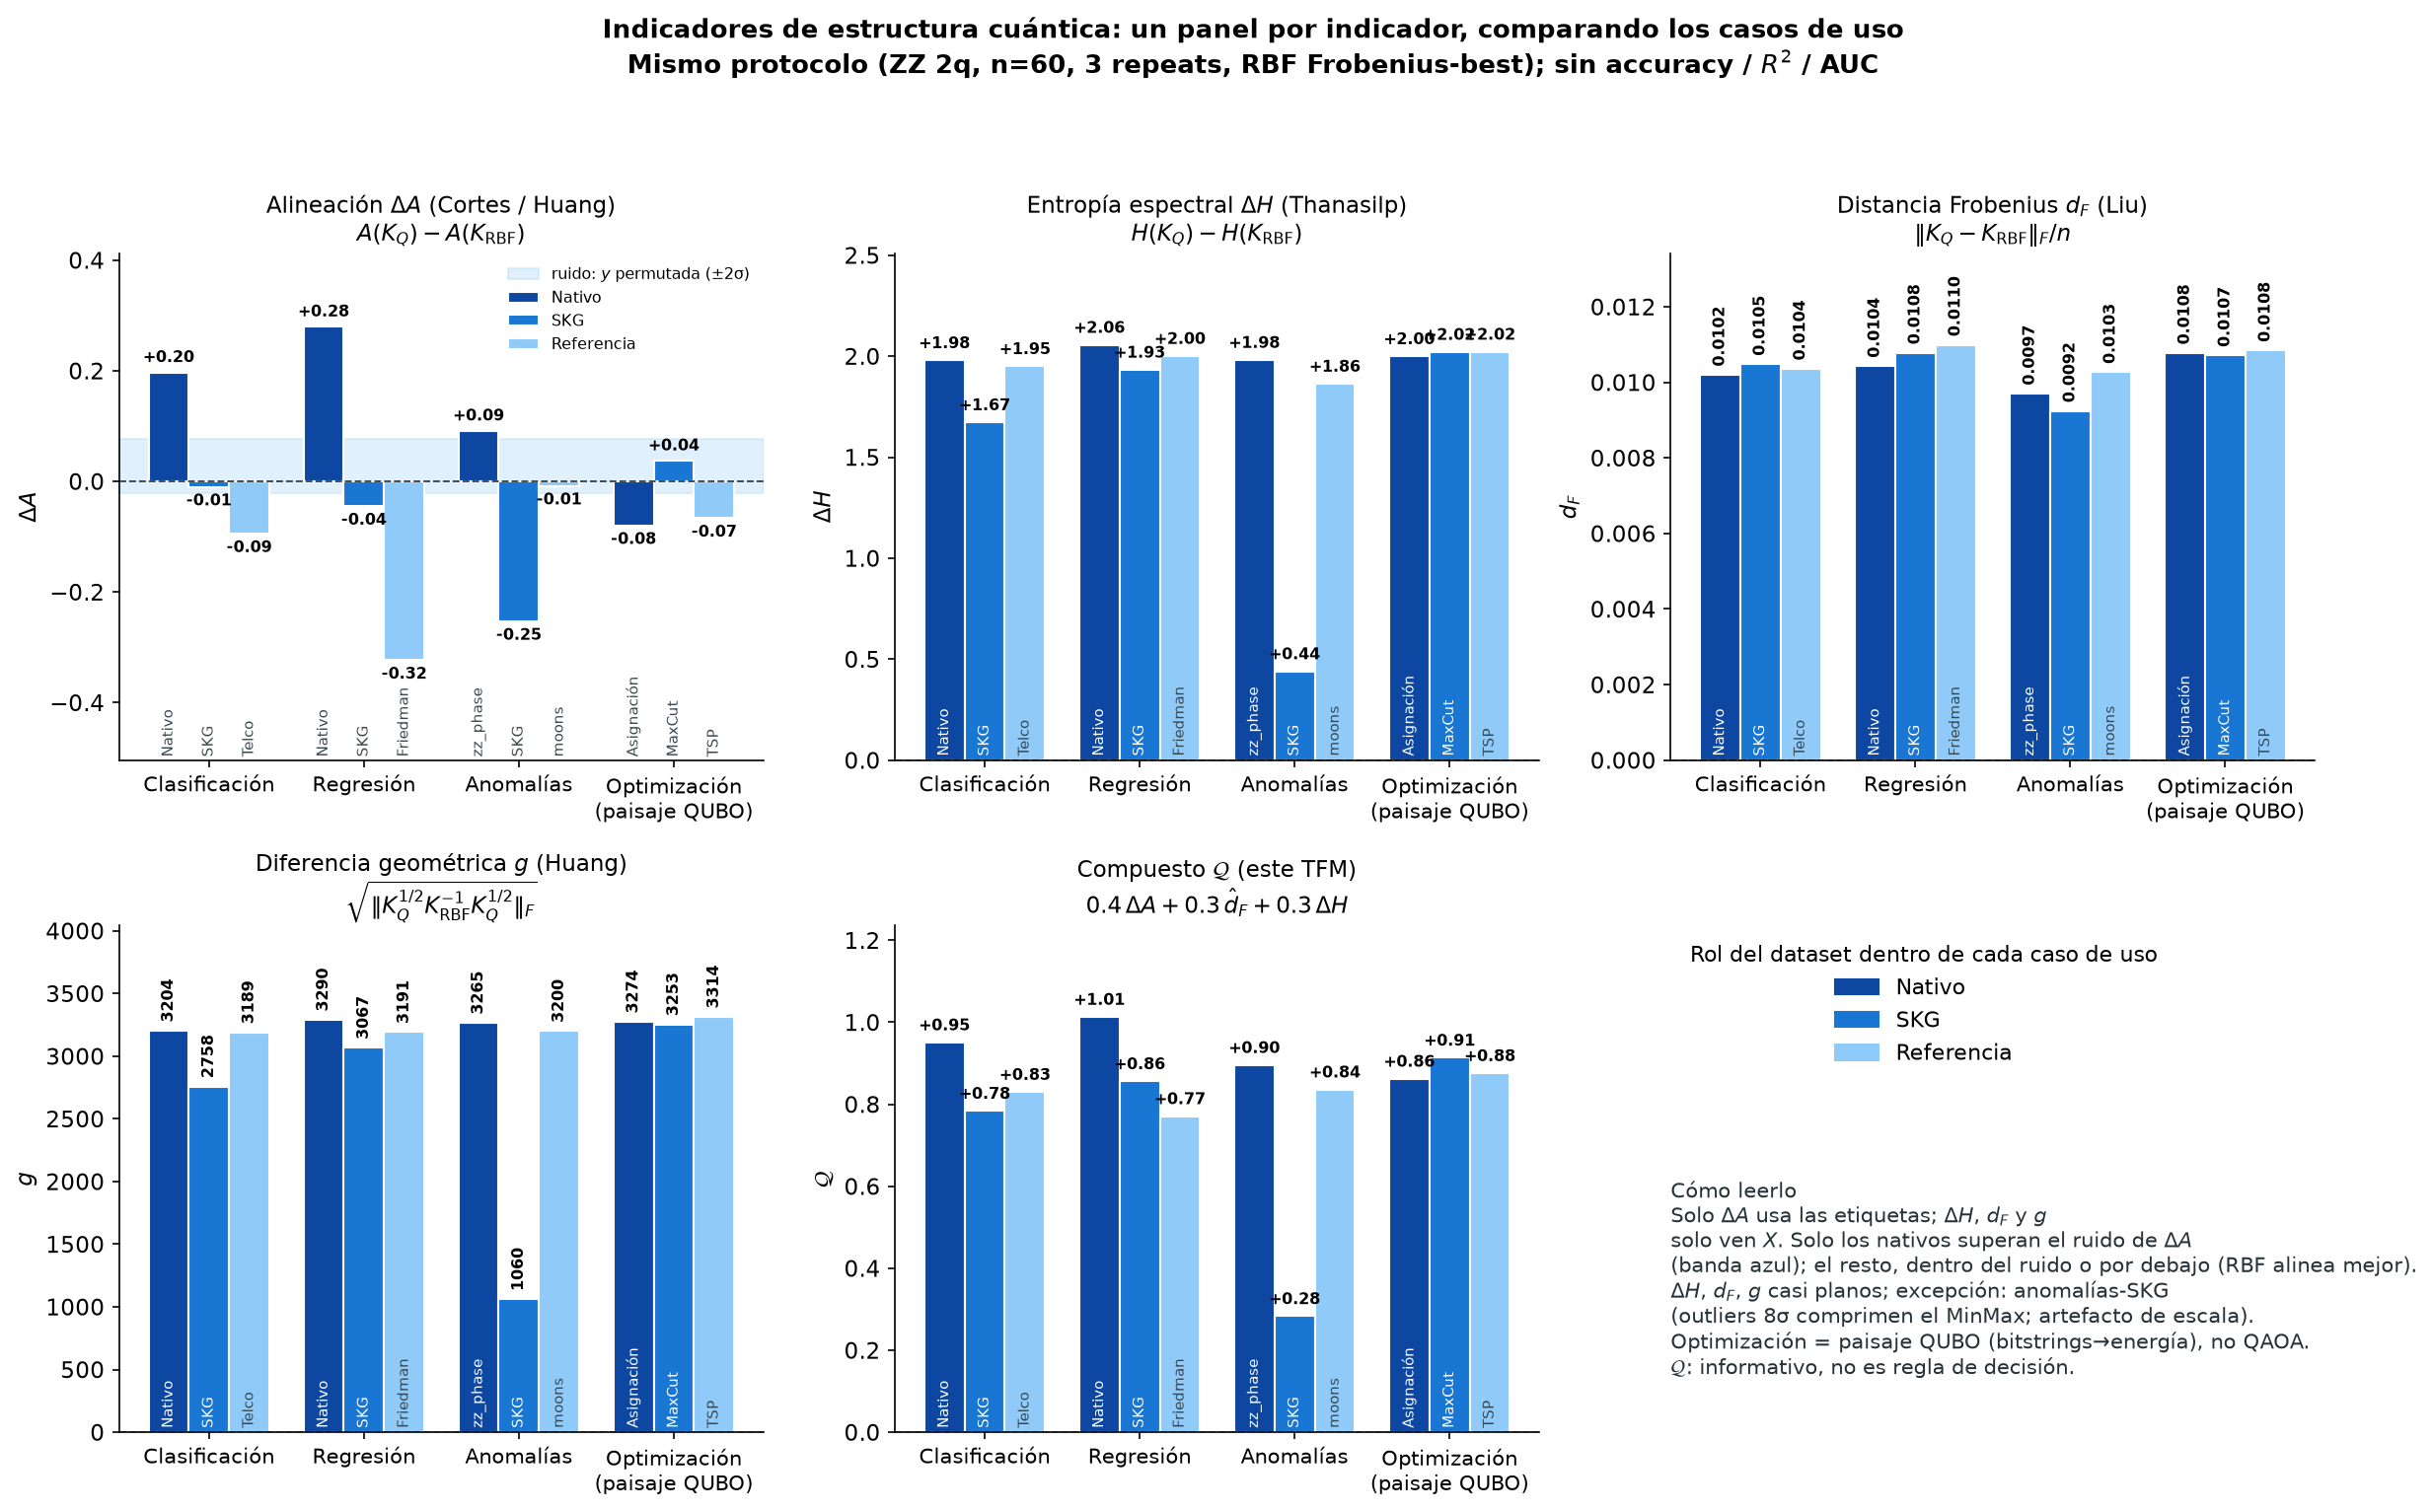

In [5]:
import generar_figuras_restantes as gf
gf.fig_08_q_vector_vs_nativo()
display(Image(filename=str(FIGURES / "08_estructura_comparativa_casos_uso.png")))

Detalle por caso de uso (mismas tres métricas y misma escala en todos): `08_perfil_clasificacion.png`,
`08_perfil_regresion.png`, `08_perfil_anomalias.png`, `08_perfil_optimizacion.png`.

## §6 — ΔA frente al control nulo

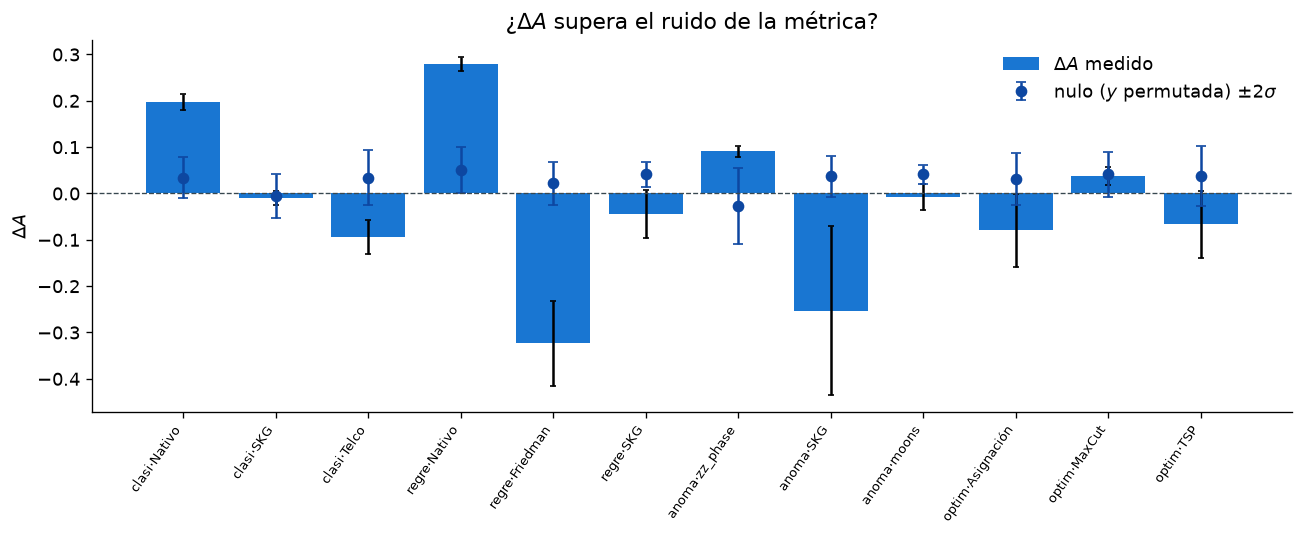

ΔA por encima del nulo (z>2):
       family  dataset  delta_A  z_vs_nulo
clasificacion   Nativo    0.197      7.313
    regresion   Nativo    0.280      9.269
    anomalias zz_phase    0.091      2.888

ΔA claramente POR DEBAJO del nulo (el RBF alinea mejor que el kernel cuántico):
       family    dataset  delta_A
clasificacion      Telco   -0.094
    regresion   Friedman   -0.323
    regresion        SKG   -0.045
    anomalias        SKG   -0.253
    anomalias      moons   -0.008
 optimizacion Asignación   -0.080
 optimizacion        TSP   -0.067


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6))
labels = [f"{r.family[:5]}·{r.dataset}" for r in df.itertuples()]
x = np.arange(len(df))
ax.bar(x, df["delta_A"], color=BLUES[1], yerr=df["delta_A_std"], capsize=2, label=r"$\Delta A$ medido")
ax.errorbar(x, df["delta_A_null"], yerr=2 * df["delta_A_null_std"], fmt="o", color=BLUES[0], capsize=3,
            label=r"nulo ($y$ permutada) $\pm2\sigma$")
ax.axhline(0, color="#37474F", ls="--", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=55, ha="right", fontsize=8)
ax.set_ylabel(r"$\Delta A$"); ax.legend(frameon=False)
ax.set_title(r"¿$\Delta A$ supera el ruido de la métrica?")
plt.tight_layout(); plt.show()

sig = df[df["z_vs_nulo"] > 2][["family", "dataset", "delta_A", "z_vs_nulo"]].round(3)
print("ΔA por encima del nulo (z>2):"); print(sig.to_string(index=False))
neg = df[df["delta_A"] < df["delta_A_null"] - 2 * df["delta_A_null_std"]][["family", "dataset", "delta_A"]].round(3)
print("\nΔA claramente POR DEBAJO del nulo (el RBF alinea mejor que el kernel cuántico):")
print(neg.to_string(index=False))

## §7 — Auditoría de lo que NO es estructura: ΔH, d_F y g

In [7]:
flat = df.groupby("family")[["delta_H", "d_F", "g"]].agg(["min", "max"]).round(4)
print(flat.to_string())
print("\nRango global sin la anomalía-SKG:")
core = df[~((df.family == "anomalias") & (df.dataset == "SKG"))]
for c in ["delta_H", "d_F", "g"]:
    print(f"  {c:8s} min={core[c].min():.4f}  max={core[c].max():.4f}  CV={core[c].std()/core[c].mean():.3f}")

              delta_H             d_F                  g           
                  min     max     min     max        min        max
family                                                             
anomalias      0.4404  1.9816  0.0092  0.0103  1060.0426  3265.3442
clasificacion  1.6732  1.9800  0.0102  0.0105  2757.7307  3203.8634
optimizacion   2.0001  2.0223  0.0107  0.0108  3253.1276  3313.9153
regresion      1.9331  2.0564  0.0104  0.0110  3066.5384  3289.7402

Rango global sin la anomalía-SKG:
  delta_H  min=1.6732  max=2.0564  CV=0.054
  d_F      min=0.0097  max=0.0110  CV=0.035
  g        min=2757.7307  max=3313.9153  CV=0.049


**Excepción explicada (no es estructura):** en *anomalías-SKG* se inyectan outliers a 8σ; `MinMax[−π,π]` se ajusta a esos extremos y
comprime a los inliers (desviación ≈ 0.2 rad sobre un rango de 2π). El kernel de los inliers queda casi constante → $\Delta H$ y $g$ bajan.
Es un **artefacto de escalado de la codificación**, no estructura cuántica detectada. La comprobación sigue:

In [8]:
from qml_v2.classification import encode_for_zz_kernel
job = next(j for j in ec.supervised_jobs() if j.family == "anomalias" and j.name == "SKG")
X, y = job.instances[0]
Xs, ys = ec.subsample(X, y, 60, 42)
Xq, _, _ = encode_for_zz_kernel(Xs, Xs, 2, 42, False)
print("Outliers en la submuestra:", int(ys.sum()), "de", len(ys))
print("Desv. estándar (rad) de los inliers tras MinMax:", Xq[ys == 0].std(0).round(3), " rango total: 2π ≈ 6.28")

Outliers en la submuestra: 6 de 60
Desv. estándar (rad) de los inliers tras MinMax: [0.206 0.24 ]  rango total: 2π ≈ 6.28


## §8 — Lectura frente a la literatura

| Hallazgo (este notebook) | Literatura | Lectura |
|---|---|---|
| $\Delta A>0$ y por encima del ruido **solo** en datos *nativos* (clasificación, regresión) y marginal en `zz_phase` | Huang et al. 2021: la ventaja requiere que los datos se generen con una estructura difícil de simular clásicamente | Coherente. El kernel ZZ solo "gana" donde se construyó el problema para él |
| $\Delta A$ por debajo del nulo en la mayoría de los datos reales (Telco, Friedman, SKG-regresión, anomalías-SKG, moons) y en asignación y TSP | Cortes et al. 2012: la alineación mide ajuste kernel–tarea, no "cuanticidad" | $\Delta A<0$ significa que el RBF se alinea mejor con $y$; **no** equivale a "estructura cuántica negativa" |
| $d_F\approx0.01$ y $g\approx3\cdot10^3$ casi idénticos en todos los casos | Liu et al. 2021: $d_F$ es la separación entre kernels; Huang 2021: $g$ grande es *necesario*, no suficiente | Con PCA(2) y MinMax, el kernel ZZ de 2 qubits tiene una forma casi universal; $d_F$ y $g$ **no discriminan** entre datasets en este protocolo |
| $\Delta H\approx1.7$–$2.1$ en todos salvo anomalías-SKG | Thanasilp et al. 2022: entropía alta ↔ concentración / kernels poco informativos | Entropía alta y plana es una advertencia de pérdida de capacidad de discriminar, no un sello de estructura |
| Optimización: $\Delta A$ dentro o por debajo del nulo; $\Delta H,d_F,g$ iguales al resto | — (no hay resultado de referencia equivalente para paisajes QUBO con este protocolo) | **Sin evidencia** de estructura cuántica en el paisaje con 2 qubits |

## §9 — Conclusiones honestas y límites

1. **Lo que sí se observa:** solo $\Delta A$ separa los datos nativos del resto; ningún dato real ni ningún paisaje de optimización supera el ruido de $\Delta A$ con signo positivo.
2. **Hipótesis rechazada:** "$\Delta A$ negativo + $\Delta H$ mínimo = estructura". $\Delta A<0$ es "el RBF alinea mejor"; el único $\Delta H$ mínimo (anomalías-SKG) es un artefacto de escala.
3. **$d_F$, $g$ y $\Delta H$ no discriminan** en este protocolo; $\mathcal Q$ queda dominado por ellos y por eso no puede usarse como decisión.
4. **Optimización:** medida sobre el paisaje QUBO (no QAOA). Con 2 qubits frente a 9–10 variables, PCA(2) conserva ≈ ⅓ de la varianza: un cuello de botella que limita cualquier conclusión. Una versión con tantos qubits como variables sería otro experimento.
5. **Límites del diseño:** 60 puntos, 3 repeticiones, 1–5 instancias por problema; un único `FeatureMap`; el baseline RBF es único. Los errores son desviaciones entre repeticiones/instancias, no intervalos de confianza formales.
6. **Corrección respecto a la versión anterior:** en la primera medición de anomalías-SKG el submuestreo reutilizaba la semilla de la inyección y seleccionaba **solo outliers** ($y$ constante → $\Delta A=0$). Aquí se submuestrea *antes* de inyectar (16 outliers sobre 160), con semilla distinta.